In [73]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import statsmodels.api as sm 
import statsmodels.formula.api as smf 

import pyfixest as pf

from tabulate import tabulate

In [2]:
# read in data
df = pd.read_csv('https://raw.githubusercontent.com/pedrohcgs/JEL-DiD/main/data/county_mortality_data.csv')

# drop 
drop_bool = df['state'].isin(["District of Columbia", "Delaware", "Massachusetts", "New York", "Vermont"])
# get index of indices to drop
drop_idx = df.loc[drop_bool].index
df.drop(index=drop_idx, inplace=True)

df['treat_year'] = df['yaca']
df['treat_year'] = df['treat_year'].fillna(0).astype(int)

# Destring covariates
cols = ['deaths', 'population_20_64', 'crude_rate_20_64', 'population_total',
        'population_20_64_hispanic', 'population_20_64_female', 'population_20_64_white',
        'unemployed', 'labor_force', 'unemp_rate', 'poverty_rate', 'median_income']
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
df = df.rename(columns={'population_total': 'total_population'})

# Build covariates and drop missing
df['perc_white']      = df['population_20_64_white']    / df['population_20_64'] * 100
df['perc_hispanic']   = df['population_20_64_hispanic'] / df['population_20_64'] * 100
df['perc_female']     = df['population_20_64_female']   / df['population_20_64'] * 100
df['unemp_rate_pc']   = df['unemp_rate'] * 100
df['median_income_k'] = df['median_income'] / 1000
df = df.dropna(subset=['crude_rate_20_64', 'population_20_64', 'perc_white', 'perc_hispanic',
                       'perc_female', 'unemp_rate_pc', 'poverty_rate', 'median_income_k'])

# Keep counties with full 11-year panel
df = df[df.groupby('county_code')['year'].transform('size') == 11]
df.loc[df['treat_year'] > 2019, 'treat_year'] = 0

# Population weight (2013 population, per county)
df['set_wt'] = (df['population_20_64'].where(df['year'] == 2013)
                .groupby(df['county_code']).transform('max'))

df.rename(columns={'crude_rate_20_64': 'crude_rate'}, inplace=True)

## Simple 2x2 diff-in-diff

Replicating results from Table 2

In [3]:
keep_row = (
    df['treat_year'].isin([0, 2014])
    & df['year'].isin([2013, 2014])
)

did_df = df.loc[keep_row].copy()

did_df['treat'] = (did_df['treat_year'] == 2014).astype(int)
did_df['post']  = (did_df['year'] == 2014).astype(int)

mean_df = did_df.groupby(['treat', 'post'])['crude_rate'].mean()
mean_df


treat  post
0      0       474.000945
       1       483.148977
1      0       419.227653
       1       428.497315
Name: crude_rate, dtype: float64

In [4]:
mean_df.reset_index().groupby('treat').diff().round(1)

,post,crude_rate
0,NaN,NaN
1,1.0,9.1
2,NaN,NaN
3,1.0,9.3


In [5]:
mean_df.reset_index().groupby('treat').diff().dropna().diff()

,post,crude_rate
1,NaN,NaN
3,0.0,0.12163


Table 3 - Regression for 2x2 did

In [6]:
# note that in patsy `treat * post` expands to `treat + post + treat * post`
did_mod = smf.wls('crude_rate ~ treat * post', data=did_df)
did_res = did_mod.fit(cov_type='cluster', cov_kwds={'groups': did_df['county_code']})
did_res.summary(slim=True)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:             crude_rate   R-squared:                       0.033
Model:                            WLS   Adj. R-squared:                  0.032
No. Observations:                4400   F-statistic:                     35.47
Covariance Type:              cluster   Prob (F-statistic):           2.23e-22
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    474.0009      4.292    110.432      0.000     465.588     482.414
treat        -54.7733      6.337     -8.643      0.000     -67.194     -42.353
post           9.1480      2.599      3.520      0.000       4.054      14.242
treat:post     0.1216      3.748      0.032      0.974      -7.225       7.468
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)
"""

In [7]:
# Function to generate significance stars
def get_significance_stars(pval):
    if pval < 0.001:
        return '****'
    elif pval < 0.01:
        return '***'
    elif pval < 0.05:
        return '**'
    elif pval < 0.1:
        return '*'
    else:
        return ''

# combining the above into a function
def get_result_array(res, keep_vars=None, name=None, add_nobs=False, show_stars=False, round_to=3):
    if keep_vars is None:
        keep_vars = res.params.index

    if show_stars:
        coef_series = (
            res.params[keep_vars].round(round_to).astype(str)           # format the estimated parameters as rounded strings
            +                                                        # use addition to add stars (if any)
            res.pvalues.apply(get_significance_stars)[keep_vars] # generate significance stars
        )
    else:
        coef_series = (
            res.params[keep_vars].round(round_to).astype(str)           # format the estimated parameters as rounded strings
        )
    coef_series.name = 'coef'  # naming series will be helpful when this is a dataframe
    tvalue_series = '(' + res.bse[keep_vars].round(round_to).astype(str) + ')' # add parentheses around formatted t-values
    tvalue_series.name = 'se'

    series_list = [coef_series, tvalue_series]
    if add_nobs:
        obs_series = pd.Series([f'{res.nobs:.0f}'], index=['_nobs'], name='obs')
        series_list = series_list + [obs_series]

    ols_res_series = pd.concat(series_list).sort_index(ascending=False)
    if name is not None:
        ols_res_series.name = name

    # reorder index
    # index_order = keep_vars + ['_nobs']
    # ols_res_series = ols_res_series.loc[index_order]
    
    return ols_res_series

ols_array = get_result_array(did_res, round_to=1)
ols_array.sort_index()


Intercept     474.0
Intercept     (4.3)
post            9.1
post          (2.6)
treat         -54.8
treat         (6.3)
treat:post      0.1
treat:post    (3.7)
dtype: str

In [68]:
fe_res = pf.feols('crude_rate ~ treat:post | county_code + year', data=did_df,
                  vcov={'CRV1': 'county_code'})
pf.etable(fe_res)

GT(_tbl_data=  __index_level_0__ __index_level_1__                   0
0              coef      treat × post  0.122 <br> (3.748)
1                fe       county_code                   -
2                fe              year                   -
3             stats      Observations               4,400
4             stats                R²               0.916, _body=<great_tables._gt_data.Body object at 0x11e767ad0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x11e7643d0>, _spanners=Spanners([SpannerInfo(spanner_id='crude_rate', spanner_level=1, spanner_label=Html(text='crude_rate'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11e767d50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11e767cd0>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11e767b10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x11e765c90>, <great_tables._gt_data.FormatInfo object at 0x11e764b90>, <great_tables._gt_data.FormatInfo object at 0x11e767350>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table

## 4. Incorporating Covariates

In [59]:
covariates = ['perc_female', 'perc_white', 'perc_hispanic', 'unemp_rate_pc', 'median_income_k', 'poverty_rate']

check_df = did_df.loc[did_df['year'] == 2013].copy() 
group_df = check_df.groupby('treat')[covariates]
mean_by_treat = group_df.mean().T
std_by_treat = group_df.std().T

mean_by_treat['norm_diff'] = (
    (mean_by_treat[1] - mean_by_treat[0]) 
    / np.sqrt((std_by_treat[1]**2 + std_by_treat[0]**2) / 2)
)

print(tabulate(mean_by_treat, headers=['Non-adopt', 'Adopt', 'Norm. diff'], floatfmt='.2f'))


                   Non-adopt    Adopt    Norm. diff
---------------  -----------  -------  ------------
perc_female            49.43    49.33         -0.03
perc_white             81.64    90.48          0.59
perc_hispanic           9.64     8.23         -0.10
unemp_rate_pc           7.61     8.01          0.16
median_income_k        43.04    47.97          0.43
poverty_rate           19.28    16.53         -0.42


In [60]:
diff_df = did_df.sort_values('year').groupby('county_code')[covariates].diff().dropna()
diff_df['treat'] = did_df.loc[diff_df.index, 'treat']
# print(tabulate(balance_table(diff_df), headers='keys', floatfmt='.2f'))

check_df = diff_df.copy() 
group_df = check_df.groupby('treat')[covariates]
mean_by_treat = group_df.mean().T
std_by_treat = group_df.std().T

mean_by_treat['norm_diff'] = (
    (mean_by_treat[1] - mean_by_treat[0]) 
    / np.sqrt((std_by_treat[1]**2 + std_by_treat[0]**2) / 2)
)

print(tabulate(mean_by_treat, headers=['Non-adopt', 'Adopt', 'Norm. diff'], floatfmt='.2f'))

                   Non-adopt    Adopt    Norm. diff
---------------  -----------  -------  ------------
perc_female            -0.02    -0.02         -0.00
perc_white             -0.21    -0.21          0.01
perc_hispanic           0.20     0.21          0.04
unemp_rate_pc          -1.16    -1.30         -0.21
median_income_k         0.98     1.11          0.06
poverty_rate           -0.55    -0.28          0.14


Table 5: regression with covariates

In [63]:
covariates = ['perc_female', 'perc_white', 'perc_hispanic', 'unemp_rate_pc', 'poverty_rate', 'median_income_k']

# 2013 covariate levels, constant within county
for c in covariates:
    did_df[c + '_2013'] = (did_df[c].where(did_df['year'] == 2013)
                           .groupby(did_df['county_code']).transform('max'))

fe = ' | county_code + year'
x13 = ' + '.join(f'{c}_2013:post' for c in covariates)  # col 2: 2013 levels x post
xt  = ' + '.join(covariates)                            # col 3: time-varying, which the FE turn into changes

fits = [
    pf.feols('crude_rate ~ treat:post' + fe,              data=did_df, vcov={'CRV1': 'county_code'}),
    pf.feols(f'crude_rate ~ treat:post + {x13}' + fe,     data=did_df, vcov={'CRV1': 'county_code'}),
    pf.feols(f'crude_rate ~ treat:post + {xt}' + fe,      data=did_df, vcov={'CRV1': 'county_code'}),
]
pf.etable(fits, keep='treat:post')

GT(_tbl_data=  __index_level_0__ __index_level_1__                   0  \
0              coef      treat × post  0.122 <br> (3.748)   
1                fe       county_code                   -   
2                fe              year                   -   
3             stats      Observations               4,400   
4             stats                R²               0.916   

                     1                    2  
0  -2.352 <br> (4.286)  -0.490 <br> (3.828)  
1                    -                    -  
2                    -                    -  
3                4,400                4,400  
4                0.916                0.917  , _body=<great_tables._gt_data.Body object at 0x129da9fd0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x11e764990>, _spanners=Spanners([SpannerInfo(spanner_id='crude_rate', spanner_level=1, spanner_label=Html(text='crude_rate'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11e7bf3d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x11e7bec10>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11e7bc950>, _formats=[<great_tables._gt_data.FormatInfo object at 0x12a7a96d0>, <great_tables._gt_data.FormatInfo object at 0x12a7fd210>, <great_tables._gt_data.FormatInfo object at 0x12a7fe8d0>, <great_tables._gt_data.FormatInfo object at 0x12a7ff310>, <great_tables._gt_data.FormatInfo object at 0x12a7fee50>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, categor

In [65]:
# one row per county: 2013 covariates + change in mortality
cs = did_df[did_df['year'] == 2013].copy()
cs['long_y'] = (did_df[did_df['year'] == 2014].set_index('county_code')['crude_rate']
                .reindex(cs['county_code']).values - cs['crude_rate'].values)

x13 = ' + '.join(f'{c}_2013' for c in covariates)

or_res = pf.feols(f'long_y ~ {x13}', data=cs[cs['treat'] == 0], vcov='hetero')        # outcome regression
ps_res = pf.feglm(f'treat ~ {x13}', data=cs, family='logit', vcov='hetero')          # propensity score

pf.etable([or_res, ps_res])

GT(_tbl_data=  __index_level_0__     __index_level_1__                      0  \
0              coef      perc_female_2013     0.042 <br> (0.860)   
1              coef       perc_white_2013     0.150 <br> (0.253)   
2              coef    perc_hispanic_2013    -0.079 <br> (0.187)   
3              coef    unemp_rate_pc_2013     1.139 <br> (1.987)   
4              coef     poverty_rate_2013     0.212 <br> (1.128)   
5              coef  median_income_k_2013     0.087 <br> (0.456)   
6              coef             Intercept  -20.909 <br> (74.560)   
7             stats          Observations                  1,222   
8             stats                    R²               0.000984   

                         1  
0     -0.041* <br> (0.016)  
1    0.059*** <br> (0.005)  
2   -0.016*** <br> (0.004)  
3    0.320*** <br> (0.026)  
4       0.035 <br> (0.019)  
5    0.082*** <br> (0.010)  
6  -10.003*** <br> (1.341)  
7                    2,200  
8                        -  , _body=<great_tables._gt_data.Body object at 0x12a860510>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x12a87ee90>, _spanners=Spanners([SpannerInfo(spanner_id='long_y', spanner_level=1, spanner_label=Html(text='long_y'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None), SpannerInfo(spanner_id='treat', spanner_level=1, spanner_label=Html(text='treat'), spanner_units=None, spanner_pattern=None, vars=['1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x12a861f10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12a862f90>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x12a83fcd0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x12a87ffd0>, <great_tables._gt_data.FormatInfo object at 0x12a87cb50>, <great_tables._gt_data.FormatInfo object at 0x12a87e290>, <great_tables._gt_data.FormatInfo object at 0x12a87f790>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', 

In [69]:
def drdid(data):
    outcome = data['long_y']
    treated = data['treat']

    # outcome model on control counties (Table 6 col 1)
    or_mod = smf.ols(f'long_y ~ {x13}', data=data[treated == 0])
    or_res = or_mod.fit()
    pred_change = or_res.predict(data)

    # propensity score model (Table 6 col 2)
    ps_mod = smf.logit(f'treat ~ {x13}', data=data)
    ps_res = ps_mod.fit(disp=0)
    pscore = ps_res.predict(data)

    # weights for control counties
    ctrl_wt = pscore * (1 - treated) / (1 - pscore)
    resid = outcome - pred_change

    return pd.Series({
        'Regression':    resid[treated == 1].mean(),
        'IPW':           outcome[treated == 1].mean() - (ctrl_wt * outcome).sum() / ctrl_wt.sum(),
        'Doubly Robust': resid[treated == 1].mean() - (ctrl_wt * resid).sum() / ctrl_wt.sum(),
    })

att_est = drdid(cs)

# bootstrap SEs: resample counties
boot_df = pd.DataFrame([
    drdid(cs.sample(frac=1, replace=True, random_state=seed).reset_index(drop=True))
    for seed in range(999)
])

results_df = pd.DataFrame({'ATT': att_est, 'SE': boot_df.std()})
print(tabulate(results_df, headers='keys', floatfmt='.2f'))

                 ATT    SE
-------------  -----  ----
Regression     -1.62  4.80
IPW            -0.86  4.81
Doubly Robust  -1.23  5.13


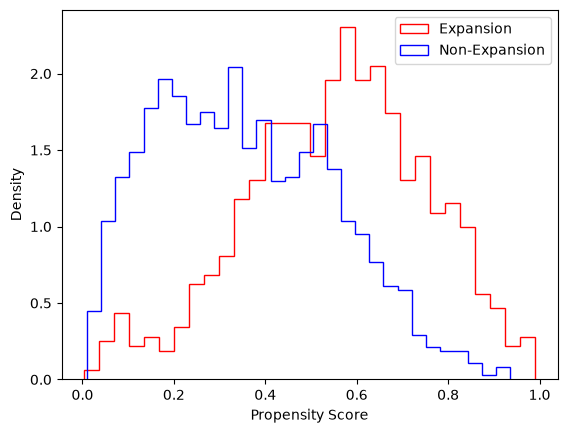

In [71]:
ps_mod = smf.logit(f'treat ~ {x13}', data=cs)
ps_res = ps_mod.fit(disp=0)
cs['pscore'] = ps_res.predict(cs)

fig, ax = plt.subplots()
ax.hist(cs.loc[cs['treat'] == 1, 'pscore'], bins=30, density=True, histtype='step', color='red', label='Expansion')
ax.hist(cs.loc[cs['treat'] == 0, 'pscore'], bins=30, density=True, histtype='step', color='blue', label='Non-Expansion')
ax.set_xlabel('Propensity Score')
ax.set_ylabel('Density')
ax.legend()

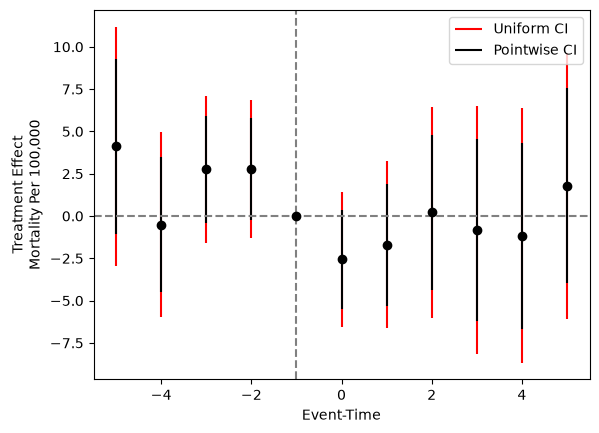

In [82]:
es_df = df[df['treat_year'].isin([0, 2014])].copy()
es_df['treat'] = (es_df['treat_year'] == 2014).astype(int)

es_res = pf.feols('crude_rate ~ i(year, treat, ref=2013) | county_code + year',
                  data=es_df, weights='set_wt', vcov={'CRV1': 'county_code'})

coefs = es_res.coef().values
ci_pointwise = es_res.confint().values
ci_uniform = es_res.confint(joint=True, seed=20240924).values
event_time = np.array([year for year in sorted(es_df['year'].unique()) if year != 2013]) - 2014

fig, ax = plt.subplots()
ax.vlines(event_time, ci_uniform[:, 0], ci_uniform[:, 1], color='red', label='Uniform CI')
ax.vlines(event_time, ci_pointwise[:, 0], ci_pointwise[:, 1], color='black', label='Pointwise CI')
ax.scatter(np.append(event_time, -1), np.append(coefs, 0), color='black', zorder=3)
ax.axhline(0, linestyle='--', color='gray')
ax.axvline(-1, linestyle='--', color='gray')
ax.set_xlabel('Event-Time')
ax.set_ylabel('Treatment Effect\nMortality Per 100,000')
ax.legend()